<a href="https://colab.research.google.com/github/JuliPerezE/SRA-TP-Filtros-Grupo5/blob/main/notebooks/01_Diseno_Matematico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- GRUPO 4: Casos asignados ---
[('LP', 'butter'), ('LP', 'bessel'), ('BP', 'butter'), ('BP', 'bessel')]

--- RESULTADOS ACTIVIDAD 1 ---
    Caso: LP BUTTER
   • Orden total H(s): 3
   • Polos (p): [-3935.08+6815.77j -7870.17   -0.j   -3935.08-6815.77j]
   • Ceros (z): []
   • Ganancia (k): 4.87e+11
   • Estabilidad: ESTABLE (Todos los Re(p) < 0)
--------------------------------------------------
    Caso: LP BESSEL
   • Orden total H(s): 3
   • Polos (p): [-4685.  +4469.65j -5916.25   -0.j   -4685.  -4469.65j]
   • Ceros (z): []
   • Ganancia (k): 2.48e+11
   • Estabilidad: ESTABLE (Todos los Re(p) < 0)
--------------------------------------------------
    Caso: BP BUTTER
   • Orden total H(s): 6
   • Polos (p): [-1499.47 -7117.2j  -4722.1  -9560.31j -1499.47 +7117.2j
 -3222.63+15296.12j -4722.1  +9560.31j -3222.63-15296.12j]
   • Ceros (z): [0.+0.j 0.+0.j 0.+0.j]
   • Ganancia (k): 8.42e+11
   • Estabilidad: ESTABLE (Todos los Re(p) < 0)
--------------------------------------------

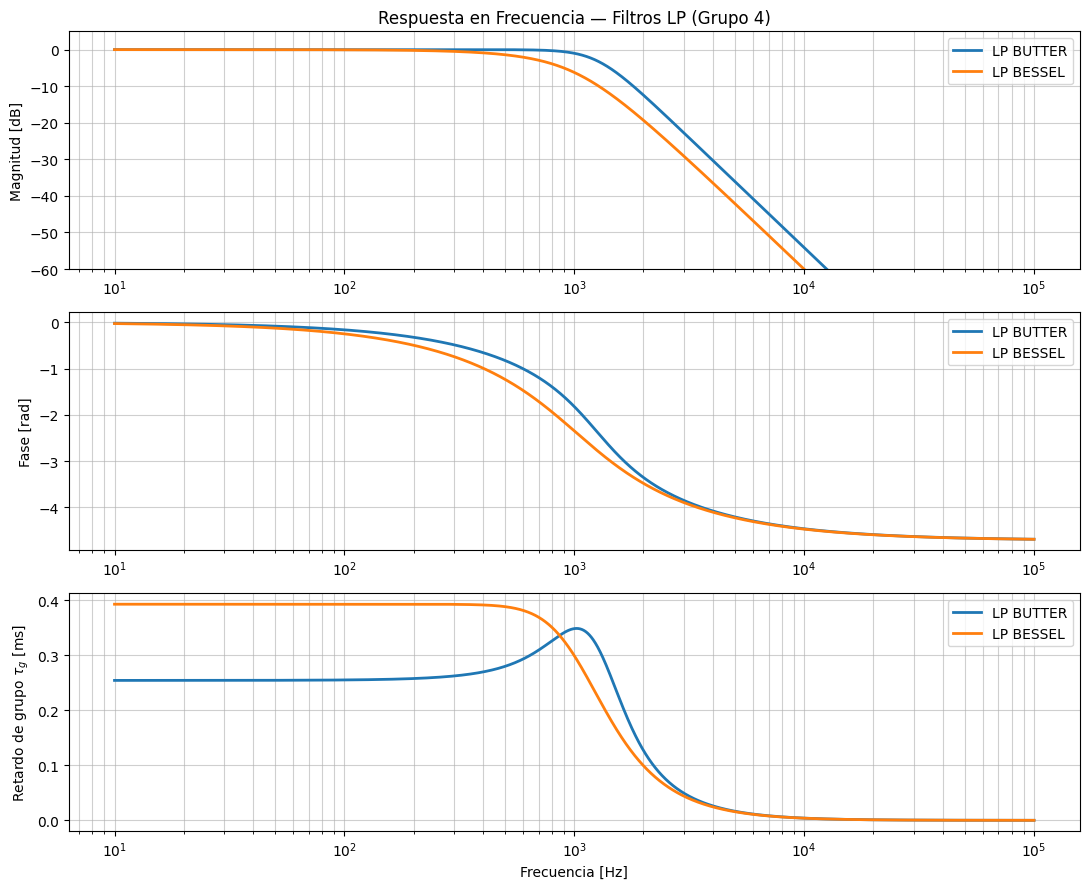

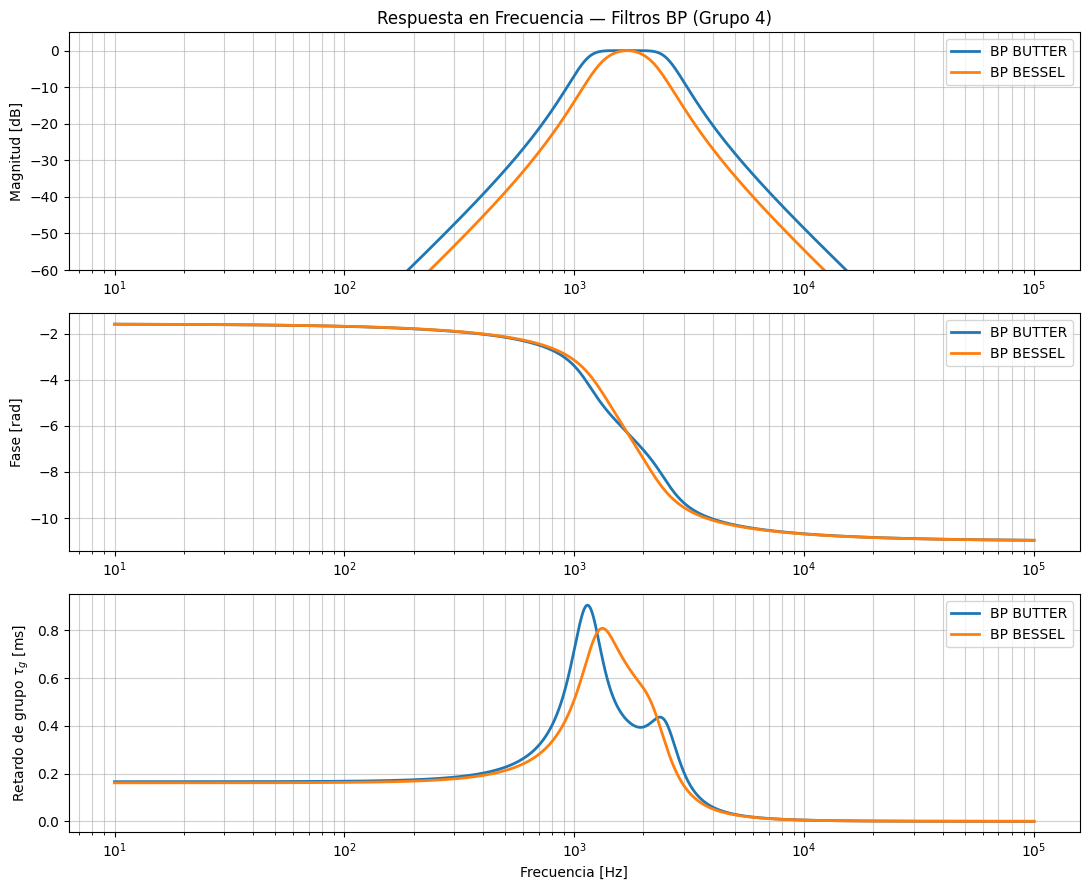


--- TABLA COMPARATIVA DE LOS CUATRO DISEÑOS ---


,Caso,Orden total,Atenuación en wp [dB],Atenuación en ws [dB],Comportamiento de Fase,Dificultad de Implementación
0,LP BUTTER,3,[-1.],[-30.26],Fase no lineal / Pico de retardo cerca del corte,Media (Orden N=3)
1,LP BESSEL,3,[-6.24],[-36.4],Fase lineal / Retardo plano en banda de paso,Baja (N=3: 1 celda RC + 1 celda Sallen-Key)
2,BP BUTTER,6,[-1. -1.],[-32.64 -31.2 ],Fase no lineal / Pico de retardo cerca del corte,Media (Orden N=6)
3,BP BESSEL,6,[-6.24 -6.24],[-38.74 -37.32],Fase lineal / Retardo plano en banda de paso,Media (Orden N=6)



SELECCIÓN DEL FILTRO PARA LA IMPLEMENTACIÓN FÍSICA:
Filtro elegido: Pasabajos (LP) Bessel de orden 3.
Justificación: Presenta retardo de grupo máximo plano en la banda de paso (respuesta al escalón sin sobrepaso). Se implementa con 1 celda pasiva RC (1° orden) + 1 celda Sallen-Key pasabajos (2° orden) usando un único op-amp doble (TL082).


In [7]:
# ==============================================================================
# CONFIGURACIÓN INICIAL Y PLANTILLA DE LA CÁTEDRA
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal

# Especificaciones de atenuación en dB
AP, AS = 1.0, 24.0

# Frecuencias de corte/rechazo en Hz para cada tipo de filtro
SPECS = {
    'LP': {'wp': [1000], 'ws': [4000], 'btype': 'lowpass'},
    'HP': {'wp': [4000], 'ws': [1000], 'btype': 'highpass'},
    'BP': {'wp': [1200, 2400], 'ws': [500, 5500], 'btype': 'bandpass'},
    'BS': {'wp': [500, 5500], 'ws': [1200, 2400], 'btype': 'bandstop'},
}

# Grupos asignados por la cátedra
GRUPOS = {
    1: (['LP', 'HP'], ['butter', 'cheby1']),
    2: (['HP', 'BP'], ['butter', 'cheby2']),
    3: (['LP', 'BS'], ['cheby1', 'ellip']),
    4: (['LP', 'BP'], ['butter', 'bessel'])
}

# SELECCIÓN DE GRUPO
GRUPO = 4

# Combinaciones de este grupo: ('LP', 'butter'), ('LP', 'bessel'), ('BP', 'butter'), ('BP', 'bessel')
casos = [(t, f) for t in GRUPOS[GRUPO][0] for f in GRUPOS[GRUPO][1]]
print(f"--- GRUPO {GRUPO}: Casos asignados ---")
print(casos)
print("=" * 60 + "\n")


# ==============================================================================
# ACTIVIDAD 1 — Función de diseño matemático y análisis de polos/estabilidad
# ==============================================================================
def disenar(tipo, familia):
    """Devuelve los ceros (z), polos (p) y ganancia (k) del filtro analógico asignado."""
    spec = SPECS[tipo]

    # Convertir frecuencias de bordes de Hz a rad/s (w = 2 * pi * f)
    wp = 2 * np.pi * np.array(spec['wp'])
    ws = 2 * np.pi * np.array(spec['ws'])
    btype = spec['btype']

    # 1. Butterworth
    if familia == 'butter':
        N, wn = signal.buttord(wp, ws, AP, AS, analog=True)
        z, p, k = signal.butter(N, wn, btype=btype, analog=True, output='zpk')

    # 2. Bessel (Excepción Bessel: Orden N = 3 fijo)
    elif familia == 'bessel':
        N = 3
        # Para LP o HP, Wn debe ser un escalar. Para BP o BS, un arreglo.
        Wn = wp[0] if len(wp) == 1 else wp
        z, p, k = signal.bessel(N, Wn, btype=btype, analog=True, output='zpk', norm='phase')

    # 3. Chebyshev 1
    elif familia == 'cheby1':
        N, wn = signal.cheb1ord(wp, ws, AP, AS, analog=True)
        z, p, k = signal.cheby1(N, AP, wn, btype=btype, analog=True, output='zpk')

    # 4. Chebyshev 2
    elif familia == 'cheby2':
        N, wn = signal.cheb2ord(wp, ws, AP, AS, analog=True)
        z, p, k = signal.cheby2(N, AS, wn, btype=btype, analog=True, output='zpk')

    # 5. Elíptico
    elif familia == 'ellip':
        N, wn = signal.ellipord(wp, ws, AP, AS, analog=True)
        z, p, k = signal.ellip(N, AP, AS, wn, btype=btype, analog=True, output='zpk')

    else:
        raise ValueError(f"Familia no reconocida: {familia}")

    return z, p, k

# Muestra en consola de los 4 diseños
print("--- RESULTADOS ACTIVIDAD 1 ---")
for tipo, familia in casos:
    z, p, k = disenar(tipo, familia)
    orden_total = len(p)
    es_estable = np.all(np.real(p) < 0)  # Polos en semiplano izquierdo

    print(f"    Caso: {tipo} {familia.upper()}")
    print(f"   • Orden total H(s): {orden_total}")
    print(f"   • Polos (p): {np.round(p, 2)}")
    print(f"   • Ceros (z): {np.round(z, 2)}")
    print(f"   • Ganancia (k): {k:.2e}")
    print(f"   • Estabilidad: {'ESTABLE (Todos los Re(p) < 0)' if es_estable else 'INESTABLE'}")
    print("-" * 50)


# ==============================================================================
# ACTIVIDAD 2 — Evaluación en frecuencia, gráficos y tabla comparativa
# ==============================================================================
# Barrido de frecuencias: 10 Hz a 100 kHz
f = np.logspace(1, 5, 2500)
w = 2 * np.pi * f  # Frecuencia en rad/s para derivadas exactas

resultados = {}

for tipo, familia in casos:
    z, p, k = disenar(tipo, familia)
    _, H = signal.freqs_zpk(z, p, k, worN=w)

    # Cálculo de magnitud, fase desenrollada y retardo de grupo
    mag_dB = 20 * np.log10(np.maximum(np.abs(H), 1e-15))
    fase_rad = np.unwrap(np.angle(H))

    # ATENCIÓN: Retardo de grupo derivando respecto a w (rad/s), NO respecto a Hz
    tau_g = -np.gradient(fase_rad, w)

    resultados[(tipo, familia)] = {
        'z': z, 'p': p, 'k': k, 'H': H,
        'mag_dB': mag_dB, 'fase_rad': fase_rad, 'tau_g': tau_g
    }

# --- GRÁFICOS (LP y BP por separado con 3 paneles cada uno) ---
for tipo in GRUPOS[GRUPO][0]:
    plt.figure(figsize=(11, 9))

    # Panel 1: Magnitud [dB]
    plt.subplot(3, 1, 1)
    for familia in GRUPOS[GRUPO][1]:
        plt.semilogx(f, resultados[(tipo, familia)]['mag_dB'], label=f"{tipo} {familia.upper()}", linewidth=2)
    plt.ylabel('Magnitud [dB]')
    plt.title(f'Respuesta en Frecuencia — Filtros {tipo} (Grupo {GRUPO})')
    plt.grid(True, which="both", alpha=0.6)
    plt.legend()
    plt.ylim(-60, 5)

    # Panel 2: Fase Desenrollada [rad]
    plt.subplot(3, 1, 2)
    for familia in GRUPOS[GRUPO][1]:
        plt.semilogx(f, resultados[(tipo, familia)]['fase_rad'], label=f"{tipo} {familia.upper()}", linewidth=2)
    plt.ylabel('Fase [rad]')
    plt.grid(True, which="both", alpha=0.6)
    plt.legend()

    # Panel 3: Retardo de Grupo [ms]
    plt.subplot(3, 1, 3)
    for familia in GRUPOS[GRUPO][1]:
        plt.semilogx(f, resultados[(tipo, familia)]['tau_g'] * 1e3, label=f"{tipo} {familia.upper()}", linewidth=2)
    plt.xlabel('Frecuencia [Hz]')
    plt.ylabel('Retardo de grupo $\\tau_g$ [ms]')
    plt.grid(True, which="both", alpha=0.6)
    plt.legend()

    plt.tight_layout()
    plt.show()

# --- TABLA COMPARATIVA DE RESULTADOS ---
filas_tabla = []

for tipo, familia in casos:
    z, p, k = resultados[(tipo, familia)]['z'], resultados[(tipo, familia)]['p'], resultados[(tipo, familia)]['k']

    wp = 2 * np.pi * np.array(SPECS[tipo]['wp'])
    ws = 2 * np.pi * np.array(SPECS[tipo]['ws'])

    _, H_wp = signal.freqs_zpk(z, p, k, worN=wp)
    _, H_ws = signal.freqs_zpk(z, p, k, worN=ws)

    att_wp = np.round(20 * np.log10(np.abs(H_wp)), 2)
    att_ws = np.round(20 * np.log10(np.abs(H_ws)), 2)

    if familia == 'bessel':
        fase_desc = "Fase lineal / Retardo plano en banda de paso"
        dificultad = "Baja (N=3: 1 celda RC + 1 celda Sallen-Key)" if tipo == 'LP' else "Media (Orden N=6)"
    else:
        fase_desc = "Fase no lineal / Pico de retardo cerca del corte"
        dificultad = f"Media (Orden N={len(p)})"

    filas_tabla.append({
        'Caso': f"{tipo} {familia.upper()}",
        'Orden total': len(p),
        'Atenuación en wp [dB]': str(att_wp),
        'Atenuación en ws [dB]': str(att_ws),
        'Comportamiento de Fase': fase_desc,
        'Dificultad de Implementación': dificultad
    })

df_tabla = pd.DataFrame(filas_tabla)
print("\n--- TABLA COMPARATIVA DE LOS CUATRO DISEÑOS ---")
display(df_tabla)

# --- JUSTIFICACIÓN PARA LA CÁTEDRA ---
print("\n" + "=" * 60)
print("SELECCIÓN DEL FILTRO PARA LA IMPLEMENTACIÓN FÍSICA:")
print("Filtro elegido: Pasabajos (LP) Bessel de orden 3.")
print("Justificación: Presenta retardo de grupo máximo plano en la banda de paso (respuesta al escalón sin sobrepaso). Se implementa con 1 celda pasiva RC (1° orden) + 1 celda Sallen-Key pasabajos (2° orden) usando un único op-amp doble (TL082).")
print("=" * 60)